# Bab 9 - Memodelkan Probabilitas dan Non-linearitas: Fungsi Aktivasi

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
**Fungsi aktivasi** adalah fungsi yang diterapkan pada output suatu layer (sebelum diteruskan ke layer berikutnya). Bab 9 menjelaskan cara memilihnya:

1. **Apa itu fungsi aktivasi?** Setiap fungsi yang diterapkan pada neuron di suatu layer selama proses prediksi (misalnya ReLU, sigmoid, tanh, softmax).
2. **Persyaratan:** fungsi aktivasi harus (a) **kontinu** (tidak ada lompatan - garis tidak terputus), (b) **monoton** (selalu naik atau selalu turun - sehingga satu input unik dipetakan ke satu output dan kemiringannya tidak berbalik), (c) **non-linear** (sehingga tumpukan layer dapat memodelkan kurva; fungsi linear tidak memberikan peningkatan representasi), dan (d) **efisien untuk dihitung**, beserta dengan turunannya.
3. **Aktivasi hidden layer standar:** **sigmoid** (memampatkan nilai ke rentang 0 hingga 1 dan digunakan untuk *probabilitas*, "aktif atau padam") dan **tanh** (memampatkan ke rentang -1 hingga 1, sehingga dapat menghasilkan korelasi *negatif* dengan memberikan nilai negatif; biasanya lebih baik daripada sigmoid untuk hidden layer).
4. **Aktivasi output layer:** bergantung pada tugas yang dikerjakan. **Output mentah (linear)** untuk regresi/nilai tak terbatas, **sigmoid** untuk prediksi ya/tidak yang independen, dan **softmax** untuk "memilih tepat satu dari N kelas" (probabilitas dengan total penjumlahan bernilai 1).
5. **Softmax** melakukan eksponensiasi dan normalisasi: `softmax(x_i) = exp(x_i) / sum(exp(x_j))`. Softmax mengubah skor mentah menjadi distribusi probabilitas dan *memperkuat pemenang (amplifies the winner)*. Karena setiap node bersaing, ia dapat menghasilkan output 0.9 untuk kelas yang benar daripada bingung oleh kelas-kelas keliru yang "mirip".
6. **Turunan fungsi aktivasi** diperlukan untuk backpropagation: `relu' = x > 0`, `sigmoid' = out * (1 - out)`, `tanh' = 1 - out^2` (ditulis dalam bentuk output-nya).
7. **Kembali ke MNIST:** mengganti ReLU dengan **tanh** pada hidden layer dan menambahkan **softmax** pada output, bersama dengan dropout dan batching, persis seperti di buku.

## Teori secara mendalam

### Mengapa harus non-linear?
Jika fungsi aktivasi bersifat linear (`f(x) = a*x`), seluruh jaringan tetap akan menyusut menjadi satu fungsi linear tunggal. Non-linearitas memberikan *korelasi selektif (selective correlation)*: suatu node dapat "padam" (ReLU, sigmoid mendekati 0) sehingga hanya berkontribusi ketika pola input relevan.

### Mengapa softmax untuk klasifikasi?
"Target" untuk MNIST adalah vektor one-hot (1 untuk digit yang benar, 0 untuk digit lainnya). Output mentah yang dilatih dengan mean squared error memperlakukan semua digit yang salah secara setara, meskipun angka '3' terlihat lebih mirip '8' daripada angka '1'. Softmax membuat jaringan memperhatikan nilai-nilai **relatif**: ia hanya menghukum *bagian probabilitas* yang diberikan kepada kelas yang salah, dan melatih suatu node agar "lebih yakin" akan secara otomatis menurunkan probabilitas kelas lainnya. Fungsi error alami yang dipasangkan dengan softmax adalah **cross-entropy**, yang turunannya menyederhanakan perhitungan gradien menjadi `prediction - target`.


In [1]:
import gzip
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('..') / 'data' / 'mnist'

def load_images(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=16).reshape(-1, 28 * 28)

def load_labels(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=8)

def one_hot(labels, n=10):
    out = np.zeros((len(labels), n))
    out[np.arange(len(labels)), labels] = 1
    return out

# buku ini melatih pada 1.000 gambar pertama dan menguji pada seluruh 10.000 gambar uji
x_train = load_images('train-images-idx3-ubyte.gz')[:1000] / 255.0
y_train_raw = load_labels('train-labels-idx1-ubyte.gz')[:1000]
y_train = one_hot(y_train_raw)
x_test = load_images('t10k-images-idx3-ubyte.gz') / 255.0
y_test_raw = load_labels('t10k-labels-idx1-ubyte.gz')
y_test = one_hot(y_test_raw)
print('train:', x_train.shape, y_train.shape, ' test:', x_test.shape, y_test.shape)

train: (1000, 784) (1000, 10)  test: (10000, 784) (10000, 10)


## 1. Fungsi aktivasi dan turunannya


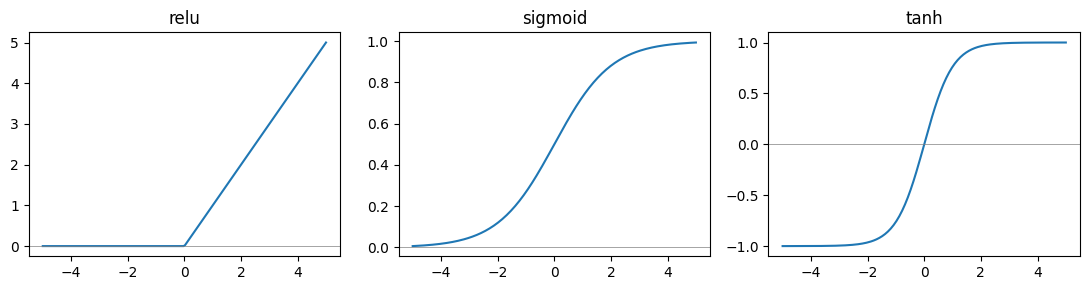

softmax of [[2.  1.  0.1]] -> [[0.659 0.242 0.099]]  sum = 1.0
softmax of 3x bigger scores -> [[0.95  0.047 0.003]] (winner is amplified)


In [2]:
def relu(x): return (x > 0) * x
def relu2deriv(out): return (out > 0).astype(float)

def sigmoid(x): return 1 / (1 + np.exp(-x))
def sigmoid2deriv(out): return out * (1 - out)

def tanh(x): return np.tanh(x)
def tanh2deriv(out): return 1 - out ** 2

def softmax(x):
    e = np.exp(x - x.max(axis=1, keepdims=True))     # kurangi nilai maksimum untuk stabilitas numerik
    return e / e.sum(axis=1, keepdims=True)

xs = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a, (name, f) in zip(ax, [('relu', relu), ('sigmoid', sigmoid), ('tanh', tanh)]):
    a.plot(xs, f(xs)); a.axhline(0, color='grey', lw=0.5); a.set_title(name)
plt.tight_layout(); plt.show()

scores = np.array([[2.0, 1.0, 0.1]])
print('softmax of', scores, '->', np.round(softmax(scores), 3), ' sum =', softmax(scores).sum())
print('softmax of 3x bigger scores ->', np.round(softmax(3 * scores), 3), '(winner is amplified)')

Sigmoid memampatkan nilai ke rentang (0, 1), tanh ke (-1, 1), dan ReLU bernilai nol untuk input negatif serta linear untuk input positif. Softmax mengonversi vektor skor menjadi probabilitas yang berjumlah 1, dan perbedaan skor yang lebih besar menghasilkan distribusi keyakinan yang lebih tajam.

## 2. MNIST dengan hidden layer tanh + output softmax + dropout + batching


In [3]:
def predict_probs(w01, w12, x):
    return softmax(tanh(x.dot(w01)).dot(w12))

def accuracy(w01, w12, x, y_raw):
    return np.mean(predict_probs(w01, w12, x).argmax(1) == y_raw)

def train(alpha=0.2, hidden=100, batch_size=100, iterations=300, dropout=True, seed=1):
    np.random.seed(seed)
    w01 = 0.02 * np.random.random((784, hidden)) - 0.01
    w12 = 0.2 * np.random.random((hidden, 10)) - 0.1
    log = []
    for it in range(iterations):
        for b in range(len(x_train) // batch_size):
            s, e = b * batch_size, (b + 1) * batch_size
            l0 = x_train[s:e]
            l1 = tanh(l0.dot(w01))
            if dropout:
                keep = np.random.randint(2, size=l1.shape) * 2.0   # 0 atau 2: matikan separuh node, gandakan sisanya
            else:
                keep = np.ones_like(l1)
            l1d = l1 * keep
            l2 = softmax(l1d.dot(w12))
            d2 = (l2 - y_train[s:e]) / batch_size           # gradien softmax + cross-entropy
            d1 = d2.dot(w12.T) * keep * tanh2deriv(l1)       # mundur melewati dropout, lalu melewati tanh
            w12 -= alpha * l1d.T.dot(d2)
            w01 -= alpha * l0.T.dot(d1)
        if it % 10 == 9:
            log.append((it + 1, accuracy(w01, w12, x_train, y_train_raw), accuracy(w01, w12, x_test, y_test_raw)))
    return np.array(log), (w01, w12)

Catatan mengenai kode: `l1` adalah output tanh, `l1d` adalah output yang sama setelah diterapkan dropout. Gradien mengalir mundur melewati faktor dropout (`keep`, bernilai 0 untuk node yang dinonaktifkan dan 2 untuk node yang dipertahankan) kemudian melewati turunan tanh.


final train accuracy: 1.000  test accuracy: 0.857


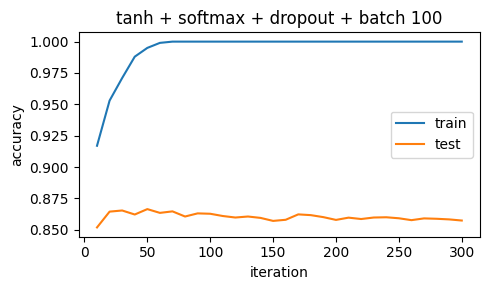

In [4]:
log9, _ = train()
print('final train accuracy: %.3f  test accuracy: %.3f' % (log9[-1, 1], log9[-1, 2]))
plt.figure(figsize=(5, 3))
plt.plot(log9[:, 0], log9[:, 1], label='train'); plt.plot(log9[:, 0], log9[:, 2], label='test')
plt.xlabel('iteration'); plt.ylabel('accuracy'); plt.legend(); plt.title('tanh + softmax + dropout + batch 100')
plt.tight_layout(); plt.show()

## 3. Apakah softmax membantu? Sebuah ablasi kecil
Bandingkan arsitektur yang sama tanpa dropout. (Kedua pengujian menggunakan hiperparameter tanpa penyesuaian/tuning dan satu random seed yang sama, sehingga perbedaan kecil tidak boleh diinterpretasikan secara berlebihan.)


In [5]:
log9_nodrop, _ = train(dropout=False)
print('without dropout -> train %.3f  test %.3f' % (log9_nodrop[-1, 1], log9_nodrop[-1, 2]))
print('with dropout    -> train %.3f  test %.3f' % (log9[-1, 1], log9[-1, 2]))

without dropout -> train 1.000  test 0.866
with dropout    -> train 1.000  test 0.857


Pada pengujian khusus ini, dropout **tidak** meningkatkan akurasi pengujian (sekitar 85.7% dengan dropout vs 86.6% tanpa dropout), dan kedua jaringan mencapai akurasi pelatihan sekitar 100%. Dropout adalah metode regularisasi yang manfaatnya bergantung pada ukuran jaringan, jumlah iterasi, dan learning rate; di sini ukuran jaringan tergolong kecil dan hiperparameter tidak dioptimalkan secara khusus untuk itu. Perhatikan juga bahwa jaringan tanh + softmax ini (akurasi uji sekitar 86%) tidak mengungguli jaringan ReLU dari Bab 8 (sekitar 88%) pada 1.000 gambar pelatihan yang sama: pemilihan fungsi aktivasi memang penting, namun demikian pula hiperparameter lainnya, dan tidak ada yang di-tuning di sini. Hal utama yang ditambahkan oleh softmax adalah *interpretasi probabilistik* dari output (output berupa probabilitas kelas yang jika dijumlahkan bernilai 1).


## Poin-poin kunci
* Fungsi aktivasi harus kontinu, monoton, dan non-linear (serta komputasinya murah).
* ReLU/tanh/sigmoid digunakan pada hidden layer; softmax adalah standar untuk output layer saat memilih satu kelas di antara banyak kelas.
* Softmax yang dipadukan dengan cross-entropy menghasilkan gradien sederhana `prediction - target` dan mengeluarkan probabilitas kelas yang berjumlah 1.
* Menggabungkan tanh + softmax + dropout + mini-batch mencapai akurasi uji sekitar 86% pada MNIST dari hanya 1.000 gambar pelatihan dalam eksperimen ini (tanpa tuning), mirip dengan jaringan ReLU pada Bab 8.
